In [2]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
import sys; sys.path.append("../utils")
from fft_sup_imports import * 
%matplotlib inline
update_rc_params('paper')
import copy

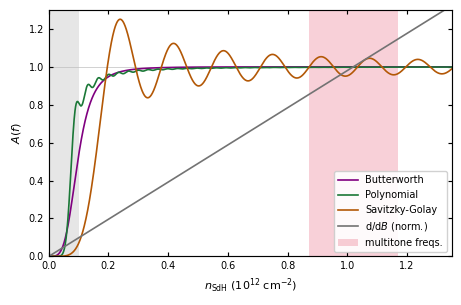

In [4]:
update_rc_params('paper')

import matplotlib.patches as mpatches
from scipy.special import spherical_jn
from scipy.signal import savgol_coeffs

H_OVER_E = 41.36                  # tesla per 1e12 cm^-2
TF_BLIMS = (1.0, 4.0)             # field window used in Fig. 3e
TF_N     = 0.5                    # density at which the Butterworth cutoff is set
TF_BWORD = 2                      # Butterworth order
TF_PDEG  = 5                      # polynomial / Savitzky-Golay order
TF_NPTS  = 600                    # points on the uniform 1/B grid
TF_TONES = (0.87, 1.17)
TF_LOWF  = 0.10                   # three-cycle resolution limit

blo, bhi = TF_BLIMS
L     = 1/blo - 1/bhi
dx    = L/TF_NPTS
fc    = 8*TF_N
cstar = TF_PDEG/(2*L)
win   = int(2*round((1/cstar)/dx/2) + 1)
c     = savgol_coeffs(win, TF_PDEG)
m     = (win - 1)//2
ns    = np.arange(-m, m + 1)

f      = np.linspace(1e-3, 1.35*H_OVER_E, 1400)
A_bw   = (f/fc)**(2*TF_BWORD) / (1 + (f/fc)**(2*TF_BWORD))
A_poly = 1 - sum((2*k + 1)*spherical_jn(k, np.pi*f*L)**2 for k in range(TF_PDEG + 1))
A_sg   = np.array([abs(1 - np.sum(c*np.exp(-2j*np.pi*ff*ns*dx))) for ff in f])
A_der  = f/(np.mean(TF_TONES)*H_OVER_E)

n_ax = f/H_OVER_E
tf_colors = ['purple', '#1B7837', '#B35806']
tf_labels = ['Butterworth', 'Polynomial', 'Savitzky-Golay']

fig, ax = plt.subplots(figsize=(5.2, 3.2))

ax.axvspan(0, TF_LOWF, color='0.9', lw=0, zorder=0)
ax.axvspan(*TF_TONES, color='crimson', lw=0, zorder=0,alpha=0.2)
ax.axhline(1, color='0.75', lw=0.5, zorder=0)

for A, col, lab in zip((A_bw, A_poly, A_sg), tf_colors, tf_labels):
    ax.plot(n_ax, A, lw=1.2, color=col, label=lab)
ax.plot(n_ax, A_der, lw=1.2, color='0.45', label=r'$\mathrm{d}/\mathrm{d}B$ (norm.)')

handles, labels = ax.get_legend_handles_labels()
handles.append(mpatches.Patch(facecolor='crimson', edgecolor='none', alpha=0.2))
labels.append('multitone freqs.')
ax.legend(handles, labels, fontsize=7, loc='lower right', framealpha=0.9)

ax.set_ylim(0, 1.3)
ax.set_xlim(0, 1.35)
ax.set_ylabel(r'$A(f)$')
ax.set_xlabel(r'$n_{\mathrm{SdH}}$ ($10^{12}$ cm$^{-2}$)')

fig.savefig("figS_transfer_functions.pdf", dpi=600, bbox_inches='tight',
            pad_inches=0.02, transparent=False)

update_rc_params('talk')